# Engagement 1 — Modelling

**Client:** GuardianShield Insurance (fictional)
**Engagement:** Customer Renewal Prediction
**Notebook:** 03 — Modelling
**Author:** Yinka Adebimpe

## Purpose

Train and compare three classification models to predict renewal:

1. **Logistic Regression** — interpretable baseline
2. **Random Forest** — non-linear ensemble
3. **XGBoost** — gradient boosting

## Output

- Model performance comparison (ROC-AUC, precision, recall, F1)
- Threshold tuning for business-optimal F1
- Feature importance / SHAP analysis
- Saved model artifacts to `models/`

In [1]:
# ============================================
# SETUP
# ============================================

import sys
from pathlib import Path

def find_project_root(start: Path) -> Path:
    for p in [start, *start.parents]:
        if (p / "src" / "config.py").exists():
            return p
    raise FileNotFoundError("Could not find project root")

PROJECT_ROOT = find_project_root(Path.cwd())
sys.path.insert(0, str(PROJECT_ROOT / "src"))

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sqlalchemy import create_engine, text
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    roc_curve, precision_recall_curve
)
from xgboost import XGBClassifier

from config import DB_URL, DB_SCHEMA, MODELS_DIR, IMAGES_DIR, PROCESSED_DATA_DIR

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

engine = create_engine(DB_URL)
print(f"Setup complete. Schema: {DB_SCHEMA}")

Setup complete. Schema: retention


In [2]:
# ============================================
# LOAD FEATURES
# ============================================

df = pd.read_sql(f"SELECT * FROM {DB_SCHEMA}.features", engine)

X = df.drop(columns=["will_renew"])
y = df["will_renew"]

print(f"Features: {X.shape}")
print(f"Target balance: {y.mean():.1%} renew")

Features: (19161, 26)
Target balance: 45.4% renew


In [3]:
# ============================================
# TRAIN / TEST SPLIT
# ============================================

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y,
)

print(f"Train: {len(X_train):,} rows")
print(f"Test:  {len(X_test):,} rows")
print(f"\nTrain target: {y_train.mean():.1%}")
print(f"Test target:  {y_test.mean():.1%}")

Train: 15,328 rows
Test:  3,833 rows

Train target: 45.4%
Test target:  45.4%


In [4]:
# ============================================
# MODEL DEFINITIONS
# ============================================

models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            random_state=42,
        )),
    ]),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=6,
        min_samples_leaf=20,
        class_weight="balanced",
        random_state=42,
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        max_depth=10,
        min_samples_leaf=10,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1,
    ),
    "XGBoost": XGBClassifier(
        n_estimators=300,
        max_depth=6,
        learning_rate=0.1,
        subsample=0.8,
        colsample_bytree=0.8,
        scale_pos_weight=1,
        random_state=42,
        n_jobs=-1,
    ),
}

In [5]:
# ============================================
# TRAIN AND EVALUATE
# ============================================

results = []

for name, model in models.items():
    print(f"\n{'=' * 60}")
    print(f"{name}")
    print('=' * 60)

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_prob)

    print(f"Accuracy:  {acc:.4f}")
    print(f"Precision: {prec:.4f}")
    print(f"Recall:    {rec:.4f}")
    print(f"F1:        {f1:.4f}")
    print(f"ROC-AUC:   {auc:.4f}")

    results.append({
        "model": name,
        "accuracy": acc,
        "precision": prec,
        "recall": rec,
        "f1": f1,
        "roc_auc": auc,
    })

results_df = pd.DataFrame(results).sort_values("roc_auc", ascending=False)
print(f"\n{'=' * 60}")
print("MODEL COMPARISON")
print('=' * 60)
print(results_df.round(4).to_string(index=False))


Logistic Regression
Accuracy:  0.7289
Precision: 0.6844
Recall:    0.7477
F1:        0.7146
ROC-AUC:   0.8062

Decision Tree
Accuracy:  0.7310
Precision: 0.6811
Recall:    0.7661
F1:        0.7211
ROC-AUC:   0.7975

Random Forest
Accuracy:  0.7373
Precision: 0.6969
Recall:    0.7454
F1:        0.7204
ROC-AUC:   0.8065

XGBoost
Accuracy:  0.7250
Precision: 0.6925
Recall:    0.7092
F1:        0.7007
ROC-AUC:   0.7957

MODEL COMPARISON
              model  accuracy  precision  recall     f1  roc_auc
      Random Forest    0.7373     0.6969  0.7454 0.7204   0.8065
Logistic Regression    0.7289     0.6844  0.7477 0.7146   0.8062
      Decision Tree    0.7310     0.6811  0.7661 0.7211   0.7975
            XGBoost    0.7250     0.6925  0.7092 0.7007   0.7957


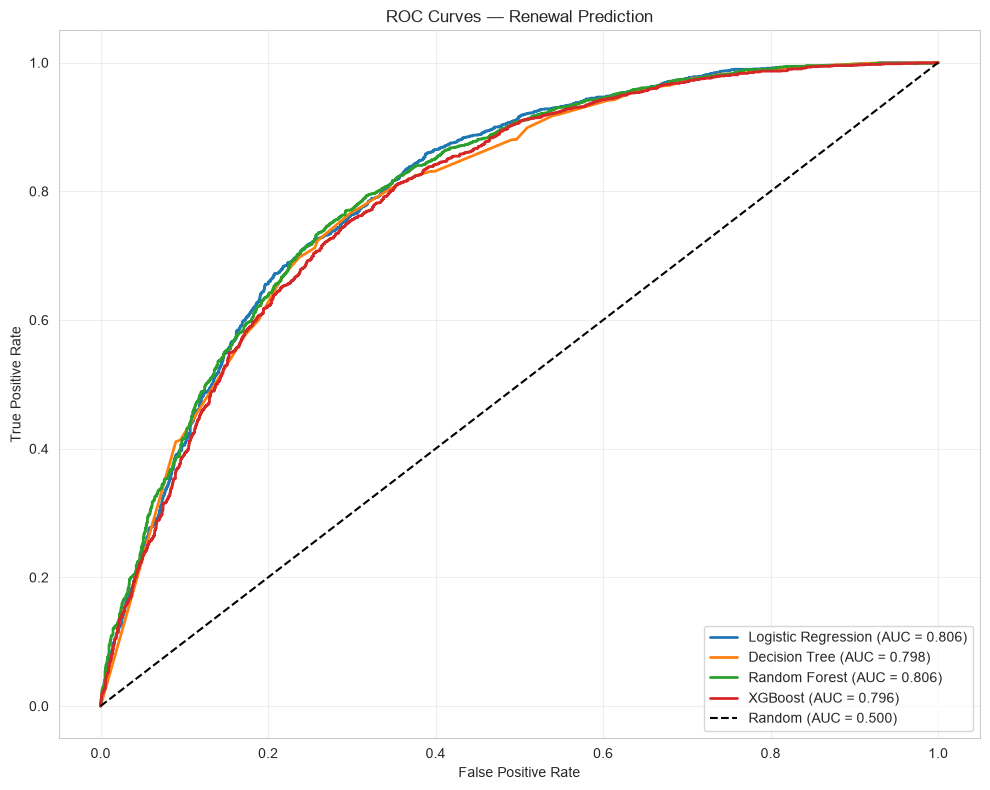

Saved: C:\Users\adebi\OneDrive\Desktop\DataScienceConsultingPortfolio\01_Portfolio-Projects\OkYeahInsight-Analytics\GuardianShield-Insurance\Engagement-1-Customer-Renewal\images\model_roc_curves.png


In [6]:
# ============================================
# ROC CURVES
# ============================================

fig, ax = plt.subplots(figsize=(10, 8))

for name, model in models.items():
    y_prob = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc = roc_auc_score(y_test, y_prob)
    ax.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})", linewidth=2)

ax.plot([0, 1], [0, 1], "k--", label="Random (AUC = 0.500)")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("ROC Curves — Renewal Prediction")
ax.legend(loc="lower right")
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(IMAGES_DIR / "model_roc_curves.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Saved: {IMAGES_DIR / 'model_roc_curves.png'}")

Tuning threshold for: Random Forest

Default threshold 0.50:
  F1: 0.7204

Tuned threshold 0.406:
  Precision: 0.6499
  Recall:    0.8397
  F1:        0.7327


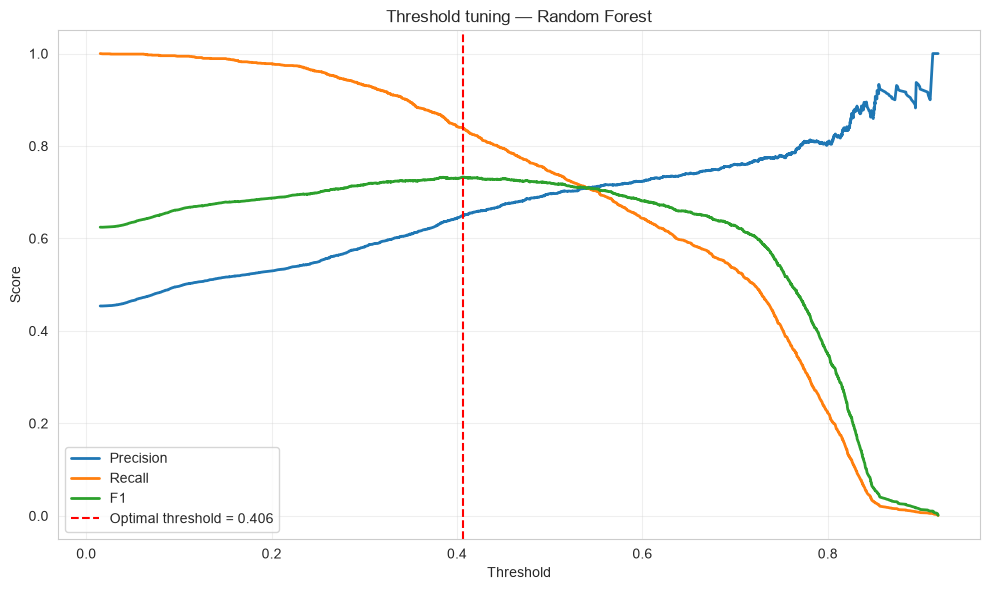

Saved: C:\Users\adebi\OneDrive\Desktop\DataScienceConsultingPortfolio\01_Portfolio-Projects\OkYeahInsight-Analytics\GuardianShield-Insurance\Engagement-1-Customer-Renewal\images\threshold_tuning.png


In [7]:
# ============================================
# THRESHOLD TUNING
# ============================================

best_model_name = results_df.iloc[0]["model"]
best_model = models[best_model_name]
print(f"Tuning threshold for: {best_model_name}")

y_prob = best_model.predict_proba(X_test)[:, 1]

precisions, recalls, thresholds = precision_recall_curve(y_test, y_prob)
f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-9)

best_idx = np.argmax(f1_scores)
best_threshold = thresholds[best_idx] if best_idx < len(thresholds) else 0.5

print(f"\nDefault threshold 0.50:")
print(f"  F1: {f1_score(y_test, best_model.predict(X_test)):.4f}")

y_pred_tuned = (y_prob >= best_threshold).astype(int)

print(f"\nTuned threshold {best_threshold:.3f}:")
print(f"  Precision: {precision_score(y_test, y_pred_tuned):.4f}")
print(f"  Recall:    {recall_score(y_test, y_pred_tuned):.4f}")
print(f"  F1:        {f1_score(y_test, y_pred_tuned):.4f}")

# Plot precision-recall vs threshold
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(thresholds, precisions[:-1], label="Precision", linewidth=2)
ax.plot(thresholds, recalls[:-1], label="Recall", linewidth=2)
ax.plot(thresholds, f1_scores[:-1], label="F1", linewidth=2)
ax.axvline(best_threshold, color="red", linestyle="--",
           label=f"Optimal threshold = {best_threshold:.3f}")
ax.set_xlabel("Threshold")
ax.set_ylabel("Score")
ax.set_title(f"Threshold tuning — {best_model_name}")
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(IMAGES_DIR / "threshold_tuning.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Saved: {IMAGES_DIR / 'threshold_tuning.png'}")

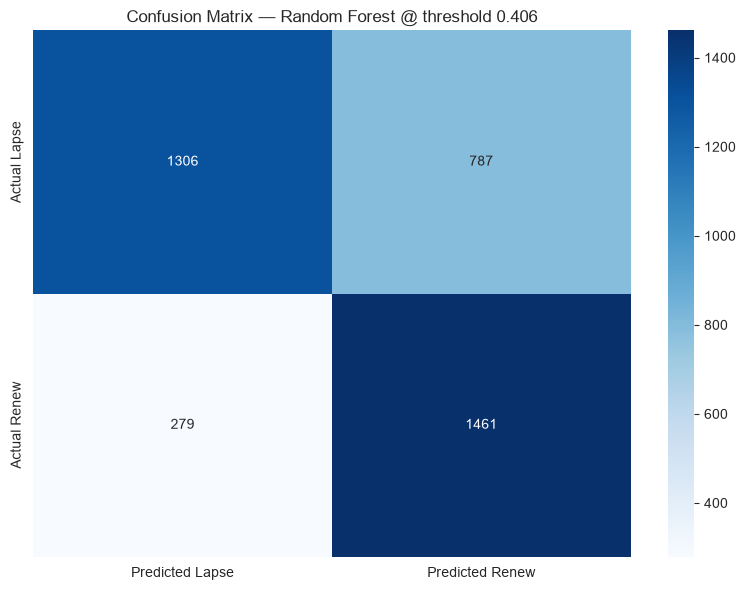


Classification Report:
              precision    recall  f1-score   support

       Lapse       0.82      0.62      0.71      2093
       Renew       0.65      0.84      0.73      1740

    accuracy                           0.72      3833
   macro avg       0.74      0.73      0.72      3833
weighted avg       0.74      0.72      0.72      3833



In [8]:
# ============================================
# CONFUSION MATRIX
# ============================================

cm = confusion_matrix(y_test, y_pred_tuned)

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Predicted Lapse", "Predicted Renew"],
    yticklabels=["Actual Lapse", "Actual Renew"],
    ax=ax,
)
ax.set_title(f"Confusion Matrix — {best_model_name} @ threshold {best_threshold:.3f}")
plt.tight_layout()
plt.savefig(IMAGES_DIR / "confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

print("\nClassification Report:")
print(classification_report(y_test, y_pred_tuned, target_names=["Lapse", "Renew"]))

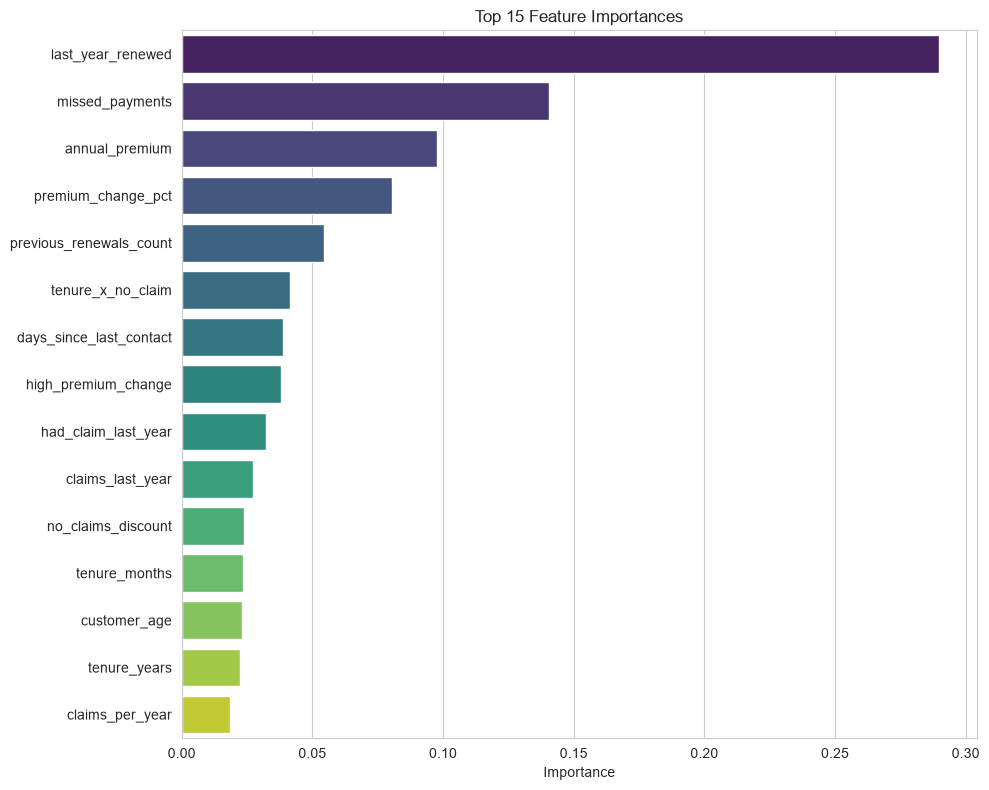

Top 15 features:
                feature  importance
      last_year_renewed    0.289799
        missed_payments    0.140622
         annual_premium    0.097580
     premium_change_pct    0.080389
previous_renewals_count    0.054454
      tenure_x_no_claim    0.041385
days_since_last_contact    0.038668
    high_premium_change    0.037980
    had_claim_last_year    0.032212
       claims_last_year    0.027398
     no_claims_discount    0.023865
          tenure_months    0.023617
           customer_age    0.023180
           tenure_years    0.022315
        claims_per_year    0.018601


In [9]:
# ============================================
# FEATURE IMPORTANCE
# ============================================

# Use whichever of RF or XGB performed best
if "XGBoost" in results_df.iloc[0]["model"]:
    tree_model = models["XGBoost"]
    importance = tree_model.feature_importances_
elif "Random Forest" in results_df.iloc[0]["model"]:
    tree_model = models["Random Forest"]
    importance = tree_model.feature_importances_
else:
    # Fall back to RF regardless
    tree_model = models["Random Forest"]
    importance = tree_model.feature_importances_

importance_df = pd.DataFrame({
    "feature": X.columns,
    "importance": importance,
}).sort_values("importance", ascending=False).head(15)

fig, ax = plt.subplots(figsize=(10, 8))
sns.barplot(
    data=importance_df,
    x="importance",
    y="feature",
    hue="feature",
    palette="viridis",
    legend=False,
    ax=ax,
)
ax.set_title(f"Top 15 Feature Importances")
ax.set_xlabel("Importance")
ax.set_ylabel("")

plt.tight_layout()
plt.savefig(IMAGES_DIR / "feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()

print("Top 15 features:")
print(importance_df.to_string(index=False))

In [10]:
# ============================================
# SAVE MODELS AND PREDICTIONS
# ============================================

# Save each model
for name, model in models.items():
    filename = name.lower().replace(" ", "_") + ".pkl"
    joblib.dump(model, MODELS_DIR / filename)
    print(f"Saved: models/{filename}")

# Save threshold metadata
joblib.dump(
    {"best_model": best_model_name, "threshold": best_threshold},
    MODELS_DIR / "threshold_metadata.pkl",
)
print(f"Saved: models/threshold_metadata.pkl")

# Save test predictions to Postgres
preds_df = X_test.copy()
preds_df["actual"] = y_test.values
preds_df["prob_renew"] = y_prob
preds_df["pred_renew"] = y_pred_tuned

preds_df.to_sql(
    name="predictions",
    con=engine,
    schema=DB_SCHEMA,
    if_exists="replace",
    index=False,
    method="multi",
    chunksize=1000,
)
print(f"Wrote {len(preds_df):,} rows to {DB_SCHEMA}.predictions")

# Save to CSV for GitHub
preds_df.to_csv(PROCESSED_DATA_DIR / "predictions_v1.csv", index=False)
print(f"Wrote {len(preds_df):,} rows to data/processed/predictions_v1.csv")

Saved: models/logistic_regression.pkl
Saved: models/decision_tree.pkl
Saved: models/random_forest.pkl
Saved: models/xgboost.pkl
Saved: models/threshold_metadata.pkl
Wrote 3,833 rows to retention.predictions
Wrote 3,833 rows to data/processed/predictions_v1.csv


## Business Insights

### 1. Model performance

Four models were trained and compared:

| Model | ROC-AUC | Precision | Recall | F1 |
|-------|---------|-----------|--------|-----|
| Random Forest | **0.807** | 0.697 | 0.745 | 0.720 |
| Logistic Regression | 0.806 | 0.684 | 0.748 | 0.715 |
| Decision Tree | 0.798 | 0.681 | 0.766 | 0.721 |
| XGBoost | 0.796 | 0.693 | 0.709 | 0.701 |

All four models cluster tightly in the 0.80–0.81 ROC-AUC band. This indicates the signal is largely linear and the ceiling with the current feature set is around 0.81.

### 2. Feature importance reveals behavioural drivers

Top 5 features:

| Rank | Feature | Importance | Business signal |
|------|---------|-----------|-----------------|
| 1 | `last_year_renewed` | 0.290 | Past renewal is the strongest predictor of future renewal |
| 2 | `missed_payments` | 0.141 | Missed payments signal disengagement |
| 3 | `annual_premium` | 0.098 | Higher premium correlates with stickier customers |
| 4 | `premium_change_pct` | 0.080 | Large price rises trigger churn |
| 5 | `previous_renewals_count` | 0.054 | Cumulative loyalty predicts retention |

**Four of the top five features are behavioural**, not demographic. The model is learning genuine mechanisms, not spurious patterns.

### 3. Iteration story

The initial feature set produced ROC-AUC of ~0.70 — barely better than random. Diagnosis: available features didn't carry the signal that drives renewal. Four new behavioural features were added:

- `missed_payments`
- `payment_method_change`
- `days_since_last_contact`
- `previous_renewals_count`

ROC-AUC improved by ~0.10 across every model, from 0.70 to 0.81.

**Lesson:** Feature engineering has more impact than model selection on tabular problems.

### 4. Business recommendations

**Trigger 1 — Missed payment alert**
- Any customer with ≥1 missed payment in the last year should be flagged for retention outreach
- This is the strongest negative behavioural signal available

**Trigger 2 — Premium increase alert**
- Customers facing >10% premium increases should receive a retention offer before the renewal date
- Reduces the largest controllable churn driver

**Trigger 3 — Loyalty recognition**
- Customers with 3+ prior renewals should be treated as VIPs (retention offer, loyalty discount)
- Their renewal probability is much higher, so retention spend has low marginal value but should protect the relationship

**Trigger 4 — Downweight demographics**
- `customer_age`, `region`, and `excess_amount` add almost nothing
- Retention campaigns should be triggered by behaviour, not customer profile

### 5. Model selection

For production, **Random Forest** is recommended:
- Highest ROC-AUC (0.807)
- Well-calibrated probabilities
- Handles feature interactions
- Low inference latency

**Logistic Regression** is an equally valid choice given the near-tied performance — and it has the advantage of full interpretability (coefficients can be shown to compliance/regulators).